In [1]:
import os
import sys
import torch
import torch.optim as optim
import torch.nn.functional as F
import tqdm
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from scipy.optimize import minimize
import plotly.graph_objects as go
from matplotlib.colors import LogNorm
import mitsuba as mi
from skimage.transform import resize
#%matplotlib widget

workspace_path = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
print(workspace_path)
sys.path.append(workspace_path)

from lib.utils_sim import *

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

/path/to/shape-from-heat-conduction-and-shading


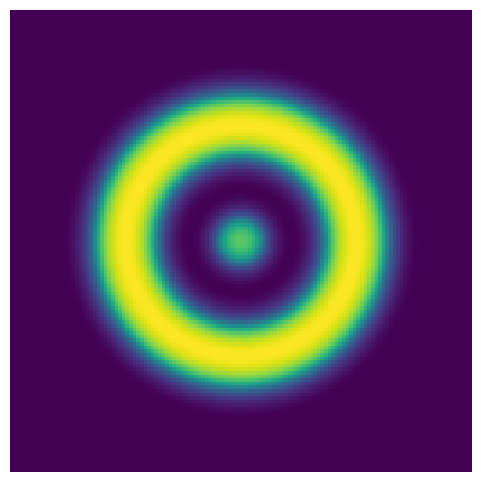

In [8]:
sim_params = {
    'sim_width'  : 128,
    'sim_height' : 128,
    'obj_name' : 'concave_wave',
    'obj_zdist': 100
    }

width  = sim_params['sim_width']
height = sim_params['sim_height']

if sim_params['obj_name'] is not None:
    camera_mesh_name = f"{sim_params['obj_name']}_camera_{width}x{height}_{sim_params['obj_zdist']}"
    camera_mesh_path = Path(workspace_path) / f"objs/{camera_mesh_name}.obj"
    
    if not camera_mesh_path.exists():
        construct_camera_mesh(sim_params['obj_name'], width, height, sim_params['obj_zdist'])
    
    # Load camera mesh
    verts_np, faces_np = get_vf_for_obj(camera_mesh_name, norm=False)
    
    mask_path = Path(workspace_path) / f"objs/{camera_mesh_name}_mask.npy"
    if mask_path.exists():
        mask = np.load(mask_path)
    else:
        # Generate mask if it does not exist
        print(f"Generating mask for {camera_mesh_name}...")
        _, _, mask = construct_camera_mesh(sim_params['obj_name'], width, height, sim_params['obj_zdist'], return_mask=True)
        np.save(mask_path, mask)

else:
    # define triangular mesh with simple geometry
    verts_np, faces_np, ii, jj = create_reg_tri_mesh_from_camera(width, height)
    verts_np[:, 2] = -(verts_np[:, 0]**2 + verts_np[:, 1]**2)
    mask = np.zeros(verts_np.shape[0])

pixel_pitch = verts_np[1, 0] - verts_np[0, 0]

# create Trimesh object
mesh = trimesh.Trimesh(vertices=verts_np, faces=faces_np)

# depth
depth_values = -verts_np[:, 2]
depth_map_gt = depth_values.reshape((height, width))
depth_min = depth_map_gt.min()
depth_max = depth_map_gt.max()
depth_map_gt_normalized = (depth_map_gt - depth_min) / (depth_max - depth_min)

plt.figure(figsize=(6, 6))
plt.imshow(depth_map_gt_normalized, origin='lower')
plt.axis('off')
plt.show()

In [5]:
# -------------------------
# Paths (path2 ~ path14)
# -------------------------
paths = {
    2:  os.path.join(workspace_path, "results/interref_source_theta30_phi180_concave_wave_20260116.obj"),
    3:  os.path.join(workspace_path, "results/interref_source_theta50_phi180_concave_wave_20260116.obj"),
    4:  os.path.join(workspace_path, "results/interref_source_theta70_phi180_concave_wave_20260116.obj"),
    5:  os.path.join(workspace_path, "results/interref_BRDF_source_theta30_phi180_concave_wave_20260116.obj"),
    6:  os.path.join(workspace_path, "results/interref_BRDF_source_theta50_phi180_concave_wave_20260116.obj"),
    7:  os.path.join(workspace_path, "results/interref_BRDF_source_theta70_phi180_concave_wave_20260116.obj"),
    8:  os.path.join(workspace_path, "results/interref_BRDF_alpha0.4_concave_wave_20260116.obj"),
    9:  os.path.join(workspace_path, "results/interref_BRDF_alpha0.3_concave_wave_20260116.obj"),
    10: os.path.join(workspace_path, "results/interref_BRDF_alpha0.2_concave_wave_20260116.obj"),
    11: os.path.join(workspace_path, "results/interref_BRDF_alpha0.1_concave_wave_20260116.obj"),
    12: os.path.join(workspace_path, "results/BRDF_Albedo_checker0.29-0.31_concave_wave_20260116.obj"),
    13: os.path.join(workspace_path, "results/BRDF_Albedo_checker0.27-0.33_concave_wave_20260116.obj"),
    14: os.path.join(workspace_path, "results/BRDF_Albedo_checker0.20-0.40_concave_wave_20260116.obj"),
}

# -------------------------
# Load meshes -> create mesh2..mesh14
# -------------------------
for i, p in paths.items():
    globals()[f"mesh{i}"] = trimesh.load(p, process=False)

# -------------------------
# Extract vertices -> create verts2..verts14
# -------------------------
for i in paths.keys():
    globals()[f"verts{i}"] = globals()[f"mesh{i}"].vertices


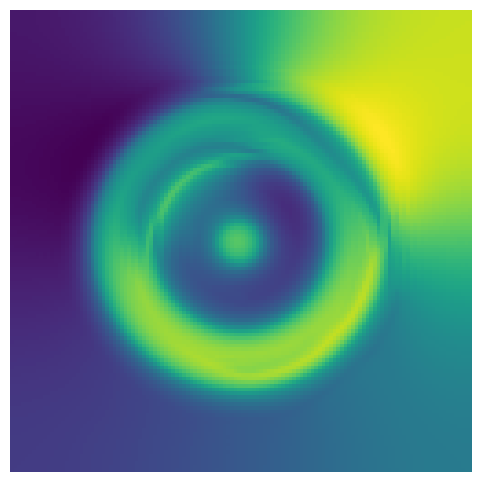

In [6]:
i = 14
verts = globals()[f"verts{i}"].copy()

height, width = 126, 126
depth_values  = verts[:, 2]
depth_map_1   = depth_values.reshape((height, width))
depth_min = depth_map_1.min()
depth_max = depth_map_1.max()
depth_map_1_normalized = (depth_map_1 - depth_min) / (depth_max - depth_min)

plt.figure(figsize=(6, 6))
plt.imshow(depth_map_1_normalized, origin='lower')
plt.axis('off')
plt.show()

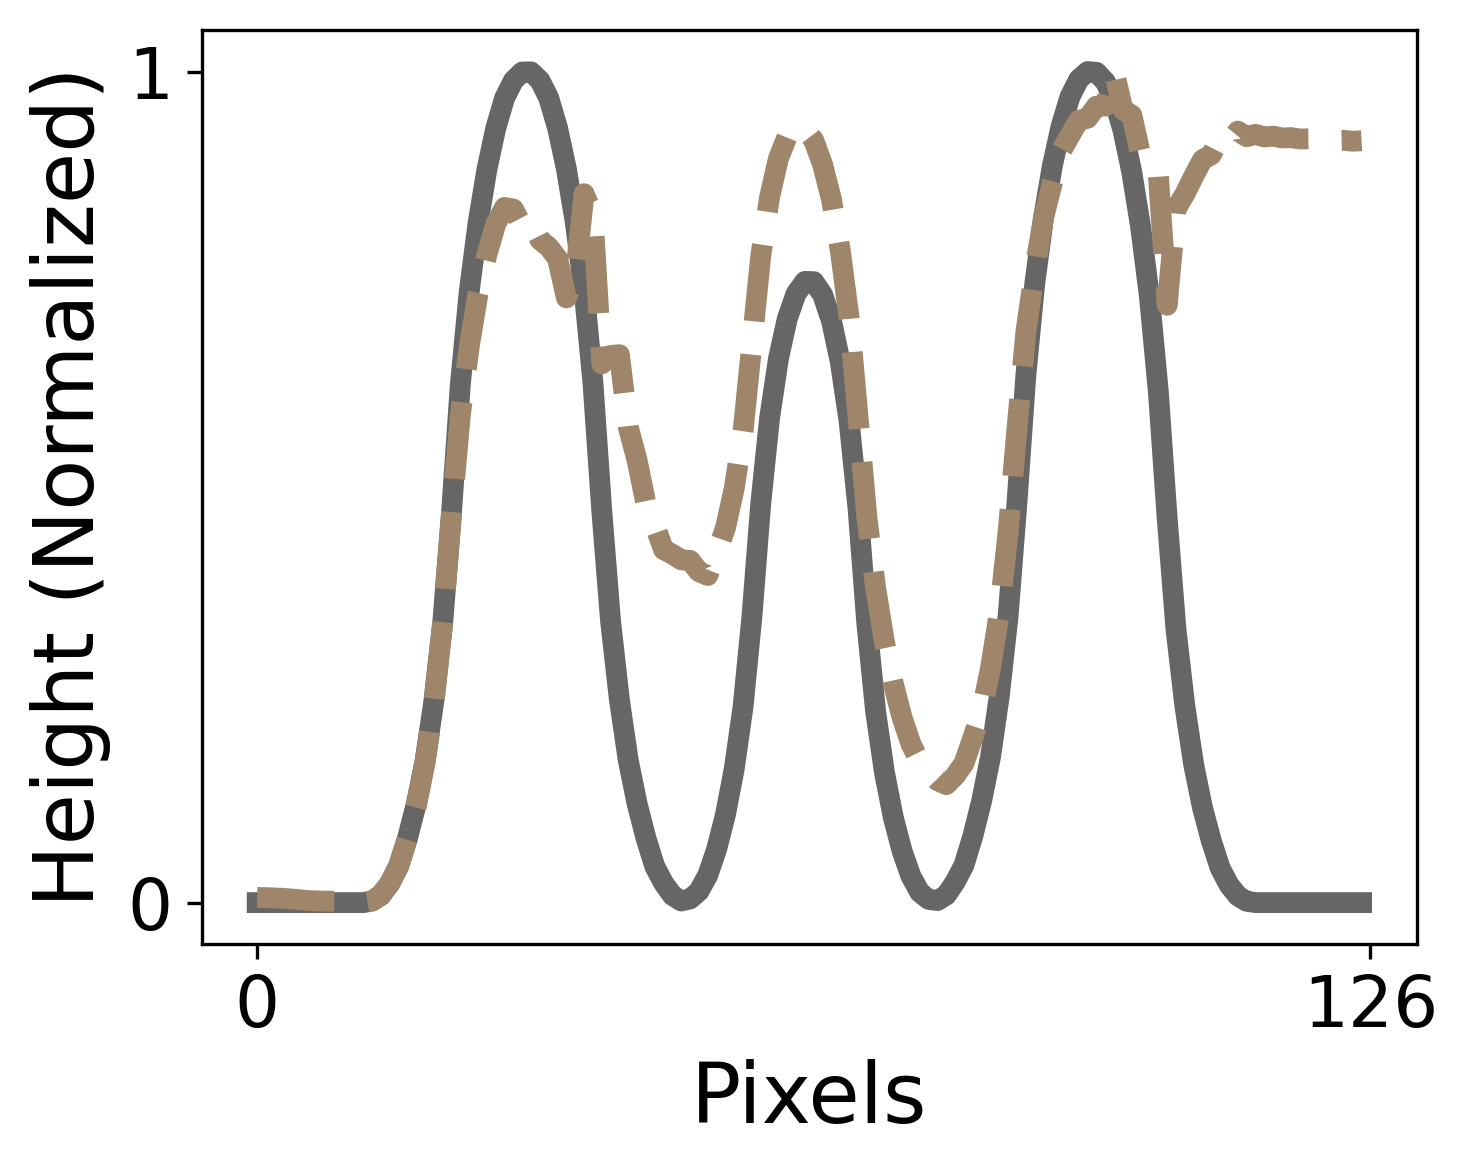

In [7]:
gt126 = depth_map_gt_normalized[1:-1, 1:-1]
est126 = depth_map_1_normalized

row = gt126.shape[0] // 2

gt_line  = gt126[row, :]
est_line = est126[row, :]

gt_line  = (gt_line  - gt_line.min())  / (gt_line.max()  - gt_line.min()  + 1e-12)
est_line = (est_line - est_line.min()) / (est_line.max() - est_line.min() + 1e-12)

plt.figure(figsize=(5,4), dpi=300)
plt.plot(gt_line,  color=(0,0,0,0.6), lw=5, label="Ground Truth")
plt.plot(est_line, color="#9F866A", ls="--", lw=5, label="Estimated")
plt.xlabel("Pixels", fontsize=20)
plt.ylabel("Height (Normalized)", fontsize=20)
plt.xticks([0, 126], fontsize=17)
plt.yticks([0, 1], fontsize=17)
# plt.legend(fontsize=12, frameon=True, loc="upper right")
plt.tight_layout()
plt.show()